# 04 EDA, Tests und Karten

- Teil 1: EDA (4.1)
- Teil 2: EDA (4.2)
- Teil 3: Statistische Tests (4.4)
- Teil 4: Karten (4.3)

In [9]:
import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import folium
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

pd.set_option("display.max_colwidth", None)
panel = pd.read_csv("../data/processed/panel_winter.csv")
d = panel[panel.covid == 0].copy()          # ohne Covid-Winter
KLASSEN = ["tief", "mittel", "hoch"]
print(len(d), "Monatsbeobachtungen,", d.bfs_nr.nunique(), "Orte")

2032 Monatsbeobachtungen, 45 Orte


## Teil 1: EDA (4.1)

folgt

## Teil 2: EDA (4.2)

folgt

## Teil 3: Statistische Tests

**Fragen:** (a) Unterscheidet sich die mittlere Winter-Zimmerauslastung zwischen den Höhenklassen? (b) Hängt Schneefall mit der Auslastung zusammen?

**Lesehilfe:** p < 0.05 heisst, ein Unterschied (bzw. Zusammenhang) dieser Grösse wäre ohne echten Unterschied unwahrscheinlich. Signifikant heisst nicht wichtig, darum steht immer auch die Grösse in Prozentpunkten (pp) dabei.

### 3.1 Eine Beobachtung pro Gemeinde

Die ANOVA verlangt unabhängige Beobachtungen. Dieselbe Gemeinde in rund 45 Wintermonaten ist nicht unabhängig, darum zuerst pro Gemeinde über alle Winter (ohne Covid) mitteln. Danach gibt es 45 Werte: 13 tief / 19 mittel / 13 hoch.

In [10]:
pro_gem = (d.groupby(["bfs_nr", "name", "hoehenklasse", "hoehenklasse_1000"])["zimmerauslastung"]
           .mean().reset_index())
gruppen = [pro_gem.loc[pro_gem.hoehenklasse == k, "zimmerauslastung"] for k in KLASSEN]

beschr = (pro_gem.groupby("hoehenklasse")["zimmerauslastung"]
          .agg(Orte="count", Mittel="mean", Median="median", Std="std").reindex(KLASSEN).round(1))
beschr

,Orte,Mittel,Median,Std
hoehenklasse,,,,
tief,13,47.9,46.2,14.1
mittel,19,53.0,55.4,10.7
hoch,13,64.0,65.9,9.6


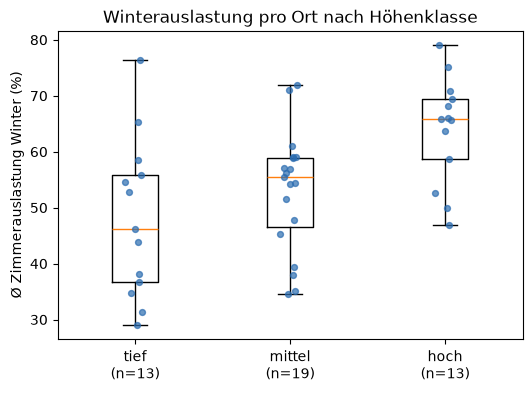

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(gruppen, showfliers=False)
for i, g in enumerate(gruppen, start=1):
    ax.scatter(np.random.default_rng(1).normal(i, 0.05, len(g)), g, s=18, alpha=0.7, color="#2b6cb0", zorder=3)
ax.set_xticks([1, 2, 3], [f"{k}\n(n={len(g)})" for k, g in zip(KLASSEN, gruppen)])
ax.set_ylabel("Ø Zimmerauslastung Winter (%)")
ax.set_title("Winterauslastung pro Ort nach Höhenklasse")
plt.show()

### 3.2 Levene, ANOVA, Kruskal-Wallis

In [12]:
levene = stats.levene(*gruppen)
anova = stats.f_oneway(*gruppen)
kruskal = stats.kruskal(*gruppen)

n = len(pro_gem)
gesamt = pro_gem.zimmerauslastung
eta2 = sum(len(g) * (g.mean() - gesamt.mean()) ** 2 for g in gruppen) / ((gesamt - gesamt.mean()) ** 2).sum()
eps2 = kruskal.statistic / (n - 1)   # Effektstärke Kruskal-Wallis

print(f"Levene:          W = {levene.statistic:.2f}, p = {levene.pvalue:.3f}")
print(f"ANOVA:           F = {anova.statistic:.2f}, p = {anova.pvalue:.4f}, eta² = {eta2:.2f}")
print(f"Kruskal-Wallis:  H = {kruskal.statistic:.2f}, p = {kruskal.pvalue:.4f}, epsilon² = {eps2:.2f}")

Levene:          W = 1.42, p = 0.253
ANOVA:           F = 6.68, p = 0.0030, eta² = 0.24
Kruskal-Wallis:  H = 10.25, p = 0.0060, epsilon² = 0.23


Levene ist nicht signifikant, die Annahme gleicher Varianzen hält also, und die klassische ANOVA ist zulässig. Weil die Gruppen klein sind (13 / 19 / 13), wird Kruskal-Wallis (rangbasiert, ohne Normalverteilungsannahme) gleich gewichtig berichtet.

### 3.3 Post-hoc: Tukey HSD

Welche Klassen unterscheiden sich? Tukey korrigiert für die drei Paarvergleiche.

In [13]:
tukey = pairwise_tukeyhsd(pro_gem.zimmerauslastung, pro_gem.hoehenklasse, alpha=0.05)
tk = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
tk

,group1,group2,meandiff,p-adj,lower,upper,reject
0,hoch,mittel,-11.0067,0.0293,-21.0740,-0.9395,True
1,hoch,tief,-16.0472,0.0027,-27.0177,-5.0767,True
2,mittel,tief,-5.0405,0.4503,-15.1077,5.0268,False


### 3.4 Spearman: Schneefall und Auslastung pro Höhenklasse

Zwei Varianten:

1. **Roh:** Monatswerte direkt korreliert (wie in der Vorlage). Problem: Saison. Januar hat am meisten Schnee, Februar die höchste Auslastung (Sportferien). Damit misst die Korrelation zum Teil nur den Kalender.
2. **Bereinigt:** Von Schneefall und Auslastung wird jeweils der Mittelwert derselben Gemeinde im selben Kalendermonat abgezogen. Übrig bleibt: «Mehr Schnee als in diesem Ort in diesem Monat üblich» vs. «Auslastung höher als üblich».

Auch hier sind die Monatswerte nicht unabhängig (gleiche Gemeinde, gleicher Winter), die p-Werte sind darum eher zu optimistisch.

In [14]:
d["schnee_abw"] = d.schneefall_cm - d.groupby(["bfs_nr", "monat"]).schneefall_cm.transform("mean")
d["ausl_abw"] = d.zimmerauslastung - d.groupby(["bfs_nr", "monat"]).zimmerauslastung.transform("mean")

kor = []
for k in KLASSEN:
    x = d[d.hoehenklasse == k]
    r1, p1 = stats.spearmanr(x.schneefall_cm, x.zimmerauslastung)
    r2, p2 = stats.spearmanr(x.schnee_abw, x.ausl_abw)
    kor.append({"Höhenklasse": k, "n": len(x), "r roh": r1, "p roh": p1, "r bereinigt": r2, "p bereinigt": p2})
kor = pd.DataFrame(kor).round(4)
kor

,Höhenklasse,n,r roh,p roh,r bereinigt,p bereinigt
0,tief,611,0.1067,0.0083,-0.0985,0.0148
1,mittel,850,0.0704,0.0402,-0.0489,0.1542
2,hoch,571,0.0602,0.1505,-0.0838,0.0454


### 3.5 Robustheit: Grenze bei 1000 m (`hoehenklasse_1000`)

Mit der 1000-m-Grenze hat «tief» nur 3 Orte. Dort wird kein Test gerechnet, nur beschreibend gezeigt.

In [15]:
(pro_gem.groupby("hoehenklasse_1000")["zimmerauslastung"]
 .agg(Orte="count", Mittel="mean", Median="median", Min="min", Max="max")
 .reindex(KLASSEN).round(1))

,Orte,Mittel,Median,Min,Max
hoehenklasse_1000,,,,,
tief,3,35.4,36.7,31.4,38.1
mittel,29,52.5,54.6,29.0,76.4
hoch,13,64.0,65.9,46.9,79.1


### 3.6 Ergebnistabelle

In [16]:
m = beschr["Mittel"]
def pp(a, b):
    row = tk[((tk.group1 == a) & (tk.group2 == b)) | ((tk.group1 == b) & (tk.group2 == a))].iloc[0]
    return row["p-adj"]

def sig(p):
    return "signifikant" if p < 0.05 else "nicht signifikant"

def stark(p, r):
    return f"{sig(p)}{', aber' if p < 0.05 else ','} sehr schwach (|r| ≈ {abs(r):.2f})"

ergebnis = pd.DataFrame([
    ["Levene (gleiche Varianzen)", f"W = {levene.statistic:.2f}", levene.pvalue,
     f"{sig(levene.pvalue)}: Varianzen gleich genug, klassische ANOVA zulässig"],
    ["ANOVA Höhenklassen", f"F = {anova.statistic:.2f}, η² = {eta2:.2f}", anova.pvalue,
     f"{sig(anova.pvalue)}: Mittel tief {m['tief']:.1f} %, mittel {m['mittel']:.1f} %, hoch {m['hoch']:.1f} %. "
     f"Höhenklasse erklärt rund {eta2:.0%} der Unterschiede zwischen den Orten"],
    ["Kruskal-Wallis Höhenklassen", f"H = {kruskal.statistic:.2f}, ε² = {eps2:.2f}", kruskal.pvalue,
     f"{sig(kruskal.pvalue)}: bestätigt die ANOVA ohne Normalverteilungsannahme"],
    ["Tukey hoch – tief", f"Δ = {m['hoch'] - m['tief']:+.1f} pp", pp("hoch", "tief"),
     f"{sig(pp('hoch', 'tief'))}: hohe Orte {m['hoch'] - m['tief']:.1f} pp besser ausgelastet"],
    ["Tukey hoch – mittel", f"Δ = {m['hoch'] - m['mittel']:+.1f} pp", pp("hoch", "mittel"),
     f"{sig(pp('hoch', 'mittel'))}: hohe Orte {m['hoch'] - m['mittel']:.1f} pp besser ausgelastet"],
    ["Tukey mittel – tief", f"Δ = {m['mittel'] - m['tief']:+.1f} pp", pp("mittel", "tief"),
     f"{sig(pp('mittel', 'tief'))}: Unterschied von {m['mittel'] - m['tief']:.1f} pp mit 13 / 19 Orten nicht sicher von Zufall zu trennen"],
] + [
    [f"Spearman Schnee–Auslastung {r['Höhenklasse']} (roh)", f"r = {r['r roh']:.2f}, n = {r['n']}", r["p roh"],
     stark(r["p roh"], r["r roh"])]
    for _, r in kor.iterrows()
] + [
    [f"Spearman Schnee–Auslastung {r['Höhenklasse']} (bereinigt)", f"r = {r['r bereinigt']:.2f}, n = {r['n']}", r["p bereinigt"],
     stark(r["p bereinigt"], r["r bereinigt"])]
    for _, r in kor.iterrows()
], columns=["Test", "Statistik", "p-Wert", "Interpretation"])
ergebnis["p-Wert"] = ergebnis["p-Wert"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
ergebnis

,Test,Statistik,p-Wert,Interpretation
0,Levene (gleiche Varianzen),W = 1.42,0.253,"nicht signifikant: Varianzen gleich genug, klassische ANOVA zulässig"
1,ANOVA Höhenklassen,"F = 6.68, η² = 0.24",0.003,"signifikant: Mittel tief 47.9 %, mittel 53.0 %, hoch 64.0 %. Höhenklasse erklärt rund 24% der Unterschiede zwischen den Orten"
2,Kruskal-Wallis Höhenklassen,"H = 10.25, ε² = 0.23",0.006,signifikant: bestätigt die ANOVA ohne Normalverteilungsannahme
3,Tukey hoch – tief,Δ = +16.1 pp,0.003,signifikant: hohe Orte 16.1 pp besser ausgelastet
4,Tukey hoch – mittel,Δ = +11.0 pp,0.029,signifikant: hohe Orte 11.0 pp besser ausgelastet
5,Tukey mittel – tief,Δ = +5.1 pp,0.450,nicht signifikant: Unterschied von 5.1 pp mit 13 / 19 Orten nicht sicher von Zufall zu trennen
6,Spearman Schnee–Auslastung tief (roh),"r = 0.11, n = 611",0.008,"signifikant, aber sehr schwach (|r| ≈ 0.11)"
7,Spearman Schnee–Auslastung mittel (roh),"r = 0.07, n = 850",0.040,"signifikant, aber sehr schwach (|r| ≈ 0.07)"
8,Spearman Schnee–Auslastung hoch (roh),"r = 0.06, n = 571",0.150,"nicht signifikant, sehr schwach (|r| ≈ 0.06)"
9,Spearman Schnee–Auslastung tief (bereinigt),"r = -0.10, n = 611",0.015,"signifikant, aber sehr schwach (|r| ≈ 0.10)"


### 3.7 Interpretation

**Höhenklassen:** Die Winter-Zimmerauslastung unterscheidet sich zwischen den Höhenklassen. ANOVA und Kruskal-Wallis sind beide signifikant (p < 0.01). Der Unterschied ist auch inhaltlich gross: Hohe Orte (über 1500 m) sind im Winter im Mittel rund 16 pp besser ausgelastet als tiefe (unter 1200 m) und rund 11 pp besser als mittlere. Zwischen tief und mittel liegen rund 5 pp, das ist mit den kleinen Gruppen nicht signifikant. Die Höhenklasse erklärt etwa ein Viertel der Unterschiede zwischen den Orten (η²), der Rest liegt an anderem (Grösse, Bekanntheit, Erreichbarkeit usw.).

**Schnee und Auslastung:** Roh hängt mehr Schneefall in tiefen und mittleren Orten minimal positiv mit der Auslastung zusammen, aber dieser Effekt ist teilweise nur Saison (Kalendermonat). Bereinigt um Ort und Monat dreht das Vorzeichen leicht ins Negative: In Monaten mit mehr Schnee als üblich ist die Auslastung nicht höher, sondern eher minimal tiefer. Mögliche Gründe sind, dass Gäste lange im Voraus buchen oder dass bei starkem Schneefall Strassen und Anlagen gesperrt sind. Alle Korrelationen sind sehr schwach (|r| ≤ 0.11), Schneefall im selben Monat erklärt also praktisch nichts von der Auslastung. Wichtiger ist die Höhenlage als dauerhafte Eigenschaft (Schneesicherheit über die Jahre) als der Schneefall im einzelnen Monat.

**Korrelation beweist keine Ursache.** Die Tests zeigen Zusammenhänge, keine Wirkung. Ob Schnee die Auslastung beeinflusst, prüft die Regression (5.x) mit Kontrollvariablen.

**Robustheit 1000-m-Grenze:** Mit der 1000-m-Grenze hat «tief» nur 3 Orte, darum dort nur beschreibend. Die Reihenfolge tief < mittel < hoch bleibt gleich (siehe 3.5).

## Teil 4: Karten (4.3)

Gemeindegrenzen (1.6) werden mit der mittleren Winter-Zimmerauslastung aus dem Panel (3.2) verknüpft.

- Mittelwert über alle Wintermonate (Dez–Mär) 2013/14–2024/25 **ohne Covid-Winter** (`covid == 0`)
- Alle Schweizer Gemeinden grau, die 45 Wintersportorte farbig
- Viele Orte sind klein, darum zusätzlich Punkte (Koordinaten aus `gemeinden.csv`), Grösse = Ø Betten

Produkte: `figures/karte_auslastung.png` (statisch, Folien) und `figures/karte_interaktiv.html` (Folium, Bonus).

In [17]:
geo = gpd.read_file("../data/processed/gemeinden.geojson")
gem = pd.read_csv("../data/processed/gemeinden.csv")
print(panel.bfs_nr.nunique(), "Orte im Panel,", len(geo), "Gemeinden in der Geometrie")

45 Orte im Panel, 2111 Gemeinden in der Geometrie


### Verknüpfen

In [18]:
mittel = (panel[panel.covid == 0]
          .groupby("bfs_nr")
          .agg(auslastung=("zimmerauslastung", "mean"), betten=("betten", "mean"))
          .reset_index())

karte = geo.merge(mittel, on="bfs_nr", how="left")   # nur die 45 Orte haben einen Wert
orte = (mittel.merge(gem[["bfs_nr", "name", "kanton", "lat", "lon", "hoehe_m", "hoehenklasse"]],
                     on="bfs_nr", how="left"))
orte = gpd.GeoDataFrame(orte, geometry=gpd.points_from_xy(orte.lon, orte.lat), crs="EPSG:4326")

# Kontrolle: alle 45 Orte gefunden (Geometrie und Koordinaten)
assert karte.auslastung.notna().sum() == 45, karte.auslastung.notna().sum()
assert orte.lat.notna().all() and len(orte) == 45
orte[["auslastung", "betten"]].describe().round(1)

,auslastung,betten
count,45.0,45.0
mean,54.7,1516.5
std,12.9,1579.0
min,29.0,187.3
25%,46.2,500.6
50%,55.8,1124.0
75%,65.2,1767.1
max,79.1,7308.9


### Statische Karte (Folien)

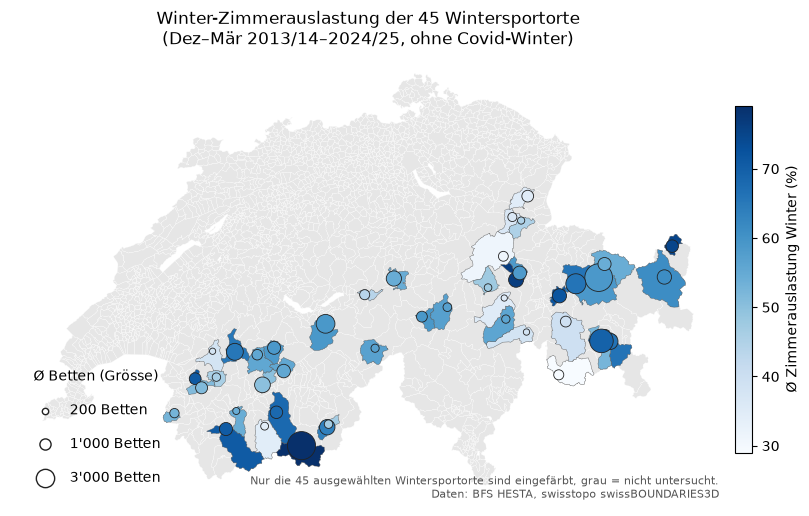

In [19]:
# Projektion LV95, damit die Schweiz nicht gestaucht aussieht
karte_lv = karte.to_crs(2056)
orte_lv = orte.to_crs(2056)

norm = mpl.colors.Normalize(vmin=orte.auslastung.min(), vmax=orte.auslastung.max())
cmap = plt.get_cmap("Blues")

def groesse(betten):
    return betten / orte.betten.max() * 400 + 10   # Fläche der Punkte ~ Betten

fig, ax = plt.subplots(figsize=(11, 7.5))
karte_lv.plot(ax=ax, color="#e6e6e6", edgecolor="white", linewidth=0.2)
karte_lv.dropna(subset=["auslastung"]).plot(ax=ax, column="auslastung", cmap=cmap, norm=norm,
                                            edgecolor="#555555", linewidth=0.3)
ax.scatter(orte_lv.geometry.x, orte_lv.geometry.y, s=groesse(orte_lv.betten),
           c=orte_lv.auslastung, cmap=cmap, norm=norm, edgecolor="#222222", linewidth=0.6, zorder=3)

# Farblegende
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6, pad=0.01)
cb.set_label("Ø Zimmerauslastung Winter (%)")

# Grössenlegende
for b in [200, 1000, 3000]:
    ax.scatter([], [], s=groesse(b), color="white", edgecolor="#222222", label=f"{b:,} Betten".replace(",", "'"))
ax.legend(title="Ø Betten (Grösse)", loc="lower left", frameon=False, labelspacing=1.4, borderpad=1)

ax.set_title("Winter-Zimmerauslastung der 45 Wintersportorte\n(Dez–Mär 2013/14–2024/25, ohne Covid-Winter)")
ax.text(0.99, 0.01, "Nur die 45 ausgewählten Wintersportorte sind eingefärbt, grau = nicht untersucht.\n"
        "Daten: BFS HESTA, swisstopo swissBOUNDARIES3D",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color="#555555")
ax.set_axis_off()
fig.savefig("../figures/karte_auslastung.png", dpi=200, bbox_inches="tight")
plt.show()

### Interaktive Karte (Bonus)

In [20]:
# Hintergrund: graue Landeskarte swisstopo (frei, ohne API-Key; CartoDB verlangt neu einen Key)
m = folium.Map(location=[46.8, 8.2], zoom_start=8,
               tiles="https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.pixelkarte-grau/default/current/3857/{z}/{x}/{y}.jpeg",
               attr="© swisstopo")

# Alle Gemeinden grau (vereinfacht, damit die HTML-Datei klein bleibt)
grau = karte[["bfs_nr", "name", "geometry"]].copy()
grau["geometry"] = grau.geometry.simplify(0.002, preserve_topology=True)
folium.GeoJson(grau, name="Alle Gemeinden (nicht untersucht)",
               style_function=lambda f: {"fillColor": "#e6e6e6", "color": "white", "weight": 0.3, "fillOpacity": 0.6},
               tooltip=folium.GeoJsonTooltip(["name"], aliases=["Gemeinde"])).add_to(m)

# 45 Wintersportorte eingefärbt
orte_poly = karte.dropna(subset=["auslastung"]).copy()
orte_poly["auslastung"] = orte_poly.auslastung.round(1)
folium.Choropleth(geo_data=orte_poly, data=orte_poly, columns=["bfs_nr", "auslastung"],
                  key_on="feature.properties.bfs_nr", fill_color="Blues", fill_opacity=0.85,
                  line_weight=0.5, name="Wintersportorte (Fläche)",
                  legend_name="Ø Zimmerauslastung Winter (%)").add_to(m)

# Punkte, Grösse = Betten, mit Infos
punkte = folium.FeatureGroup(name="Wintersportorte (Punkte, Grösse = Betten)")
for _, r in orte.iterrows():
    folium.CircleMarker(
        location=[r.lat, r.lon], radius=(r.betten / orte.betten.max()) ** 0.5 * 18 + 3,
        color="#222222", weight=1, fill=True, fill_color=mpl.colors.to_hex(cmap(norm(r.auslastung))), fill_opacity=0.9,
        tooltip=(f"<b>{r['name']}</b> ({r.kanton})<br>"
                 f"Ø Zimmerauslastung Winter: {r.auslastung:.1f} %<br>"
                 f"Ø Betten: {r.betten:,.0f}<br>".replace(",", "'") +
                 f"Höhe: {r.hoehe_m:.0f} m ({r.hoehenklasse})")
    ).add_to(punkte)
punkte.add_to(m)

hinweis = ('<div style="position:fixed;bottom:20px;left:20px;z-index:9999;background:white;padding:6px 10px;'
           'border:1px solid #999;font-size:12px;max-width:320px">'
           '<b>Winter-Zimmerauslastung der 45 Wintersportorte</b><br>'
           'Dez–Mär 2013/14–2024/25, ohne Covid-Winter.<br>'
           'Nur die 45 ausgewählten Wintersportorte sind eingefärbt, grau = nicht untersucht. '
           'Punktgrösse = Ø Betten.</div>')
m.get_root().html.add_child(folium.Element(hinweis))
folium.LayerControl(collapsed=False).add_to(m)
m.save("../figures/karte_interaktiv.html")

print(f"{os.path.getsize('../figures/karte_interaktiv.html') / 1e6:.1f} MB")

2.4 MB
